# Задание 1

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import random
import math
from tqdm import tqdm

In [2]:
def sigmoid(z):
    z = np.array(z)
    return 1 / (1 + np.exp(-z))

In [3]:
class Neuron:
    def __init__(self, n_inputs):
        # инициализация случайных весов и смещения
        self.w = np.array([random.uniform(-1, 1) for _ in range(n_inputs)])
        self.b = random.uniform(-1, 1)
        self.inputs = np.array([])
        self.out = 0.0
        self.delta = 0.0

    # прямой проход
    def forward(self, inputs):
        self.inputs = inputs
        z = np.dot(self.w, self.inputs) + self.b # линейная комбинация весов и входов + смещение
        self.out = sigmoid(z)
        return self.out

    # обновление весов
    def update(self, lr):
        self.w -= lr * self.delta * self.inputs
        self.b -= lr * self.delta

class Layer:
    def __init__(self, n_inputs, n_neurons):
        self.neurons = [Neuron(n_inputs) for i in range(n_neurons)]

    def forward(self, inputs):
        inputs = np.asarray(inputs)
        return [n.forward(inputs) for n in self.neurons]

class Network:
    def __init__(self, sizes):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Layer(sizes[i], sizes[i+1]))

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, target): # backprop
        output_layer = self.layers[-1]

        for neuron, expected in zip(output_layer.neurons, target):
            error = neuron.out - expected
            neuron.delta = error * neuron.out * (1 - neuron.out)

        for i in reversed(range(len(self.layers) - 1)):
            layer = self.layers[i]
            next_layer = self.layers[i + 1]

            for j, neuron in enumerate(layer.neurons):
                error = 0
                for next_neuron in next_layer.neurons:
                    error += next_neuron.w[j] * next_neuron.delta
                neuron.delta = error * neuron.out * (1 - neuron.out)

    def train(self, inputs_list, targets_list, epochs=10000, learning_rate=0.5, verbose=False):
        for epoch in tqdm(range(epochs)):
            total_loss = 0

            for inputs, targets in zip(inputs_list, targets_list):
                outputs = self.forward(inputs)

                for output, target in zip(outputs, targets):
                    total_loss += (output - target) ** 2

                self.backward(targets)

                for layer in self.layers:
                    for neuron in layer.neurons:
                        neuron.update(learning_rate)
            if verbose:
                print(f"Epoch {epoch}, Loss: {total_loss / len(inputs_list)}")

    def predict(self, inputs):
        return self.forward(inputs)

In [4]:
x = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_or = np.array([[0], [1], [1], [1]])
y_and = np.array([[0], [0], [0], [1]])
y_xor = np.array([[0], [1], [1], [0]])

In [5]:
mlp = Network([2, 2, 1])
mlp.train(x, y_xor, epochs=10000, learning_rate=0.5)

print(mlp.predict(np.array([0, 0])))
print(mlp.predict(np.array([0, 1])))
print(mlp.predict(np.array([1, 0])))
print(mlp.predict(np.array([1, 1])))

100%|██████████| 10000/10000 [00:00<00:00, 13608.61it/s]

[np.float64(0.018906808416239353)]
[np.float64(0.9838116349738545)]
[np.float64(0.9835092749954046)]
[np.float64(0.01707561518586172)]


# Задание 2

In [6]:
import tensorflow as tf

In [7]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_test = x_test.reshape(len(x_test), -1) / 255.0
x_train = x_train.reshape(len(x_train), -1) / 255.0

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

y_train = np.eye(10)[y_train]     
y_test_labels = y_test
y_test = np.eye(10)[y_test]

print(x_train.min(), x_train.max(), x_train.shape)

(60000, 784) (60000,)
(10000, 784) (10000,)
0.0 1.0 (60000, 784)


In [8]:
mlp = Network([x_train.shape[1], 32, 10])
mlp.train(x_train, y_train, epochs=30, learning_rate=0.01, verbose=True)

  3%|▎         | 1/30 [00:15<07:22, 15.28s/it]

Epoch 0, Loss: 0.5953244085988311


  7%|▋         | 2/30 [00:30<07:08, 15.32s/it]

Epoch 1, Loss: 0.3162125494064984


 10%|█         | 3/30 [00:45<06:51, 15.23s/it]

...

Epoch 27, Loss: 0.09543065013404624


 97%|█████████▋| 29/30 [07:20<00:15, 15.29s/it]

Epoch 28, Loss: 0.09428275513621684


100%|██████████| 30/30 [07:35<00:00, 15.20s/it]

Epoch 29, Loss: 0.09318562753419034


# Задание 3

In [18]:
import tensorflow as tf
from tensorflow.keras import layers, models

num_classes = 10
input_shape = (28, 28, 1)

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test = tf.keras.utils.to_categorical(y_test, num_classes)


model = models.Sequential([
    layers.Flatten(input_shape=(28, 28)),  
    layers.Dense(128, activation='sigmoid'),   
    layers.Dense(10, activation='sigmoid')])

batch_size = 128
epochs = 30

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8533 - loss: 0.6197 - val_accuracy: 0.9280 - val_loss: 0.2764
Epoch 2/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9188 - loss: 0.2885 - val_accuracy: 0.9433 - val_loss: 0.2088
Epoch 3/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9344 - loss: 0.2311 - val_accuracy: 0.9527 - val_loss: 0.1745
Epoch 4/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9447 - loss: 0.1943 - val_accuracy: 0.9588 - val_loss: 0.1580
Epoch 5/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9517 - loss: 0.1675 - val_accuracy: 0.9637 - val_loss: 0.1391
Epoch 6/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9579 - loss: 0.1458 - val_accuracy: 0.9667 - val_loss: 0.1231
Epoch 7/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9631 - loss: 0.1284 - val_accuracy: 0.9680 - val_loss: 0.1153
Epoch 8/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9681 - loss: 0.1138 - val_accuracy: 0.

In [22]:
(_x_train, _y_train), (_x_test, _y_test) = tf.keras.datasets.mnist.load_data()

_x_test = _x_test.reshape(len(_x_test), -1) / 255.0
_x_train = _x_train.reshape(len(_x_train), -1) / 255.0

_y_train = np.eye(10)[_y_train]     
_y_test_labels = _y_test
_y_test = np.eye(10)[_y_test]
true_counter = 0
for i in range(len(_x_test)):
    if np.argmax(mlp.predict(_x_test[i])):
        true_counter += 1
print(f"Точность модели NumPy: {true_counter / len(x_test)}")

score = model.evaluate(x_test, y_test, verbose=0)
print("Точность модели Keras:", score[1])

Точность модели NumPy: 0.8986
Точность модели Keras: 0.9765999913215637


# Задание 4

Предсказание модели NumPy: 3
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Предсказание модели Keras: 3


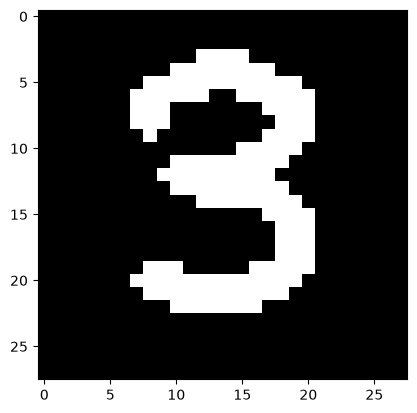

In [44]:
from PIL import Image

test_img = Image.open('knn_example.png').convert("1")
_test_img_array = np.array(test_img).flatten()
test_img_array = np.array(test_img).reshape(1, 28, 28)

print(f"Предсказание модели NumPy: {np.argmax(mlp.predict(_test_img_array))}")
print(f"Предсказание модели Keras: {np.argmax(model.predict(test_img_array))}")
plt.imshow(np.array(test_img), cmap='gray')
plt.show()